[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/josterri/predicting-the-next-words-notebooks/blob/main/ch06-short_workbook.ipynb)

# Three scores, three weights and one context vector

A decoder writing `black` scores the three French words `le`, `chat` and
`noir`. How much of its attention does each word get, and which vector does
the decoder read from them?

In [1]:
#@title Setup: run this cell first
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

WORDS = ["le", "chat", "noir"]
# The lecture's three encoder states, two numbers each; the query scores each one as a key.
STATES = np.array([[1.0, 0.0], [1.0, 1.0], [0.0, 2.0]])
RED, GREY = "C3", "0.6"
plt.rcParams.update({"xtick.labelsize": 9, "ytick.labelsize": 8, "legend.fontsize": 8})


class Refused(Exception):  # a setting a cell refuses: Colab prints the one sentence, without the stack
    _render_traceback_ = lambda self: [str(self)]  # noqa: E731


def numbers(name, x, n, what):  # n finite numbers, or one sentence saying what to type
    try:
        v = np.asarray(x, dtype=float)
    except (TypeError, ValueError):
        v = np.array([])
    if v.shape != (n,) or not np.isfinite(v).all() or (n == 2 and abs(v).max() > 3):
        raise Refused(f"{name} is {x!r}: {name} takes {what}.")
    return v


def softmax(scores):  # e to each score, divided by the sum: positive weights that add to 1
    s = numbers("SCORES", scores, 3, "three numbers in brackets, one each for le, chat and noir, such as [0, 1, 2]")
    e = np.exp(s - s.max())  # the largest score subtracted first: the same weights, and no overflow
    return e / e.sum()


def fmt(v):  # a computed vector as (0.335, 1.575)
    return "(" + ", ".join(f"{x + 0.0:.3f}" for x in v) + ")"


def vec(v):  # a typed vector as (0, 1)
    return "(" + ", ".join(f"{x + 0.0:g}" for x in v) + ")"


def listed(v):  # numbers as 0, 1 and 2
    v = [f"{x + 0.0:g}" for x in v]
    return ", ".join(v[:-1]) + " and " + v[-1]


def named(w):  # weights as le 0.090, chat 0.245, noir 0.665
    return ", ".join(f"{a} {b:.3f}" for a, b in zip(WORDS, w))


def weight_bars(ax, scores):  # each word's score under it and its weight as a bar, the largest in red
    w = softmax(scores)
    drawn = ax.bar([f"{a}\nscore {x + 0.0:g}" for a, x in zip(WORDS, scores)], w,
                   color=[RED if np.isclose(x, w.max()) else GREY for x in w])
    ax.bar_label(drawn, fmt="%.3f", fontsize=9)
    ax.legend(handles=[Patch(color=RED, label="largest weight")], loc="upper left")
    ax.set(ylim=(0, 1.1), ylabel="weight", title="softmax turns the scores into weights")
    return w


def weights_bars(scores):  # step 1; a refused setting draws no empty chart
    print(f"weights: {named(softmax(scores))}")
    fig, ax = plt.subplots(figsize=(5, 2.8), layout="constrained")
    weight_bars(ax, scores)
    plt.show()


def attend(query):  # step 2: the query dotted with each state, the weights, the context vector
    q = numbers("QUERY", query, 2, "two numbers from -3 to 3 in brackets, such as [0, 1]")
    s = STATES @ q
    w = softmax(s)
    print(f"dot products of the query {vec(q)} with " + ", ".join(f"{a} {vec(h)}" for a, h in zip(WORDS, STATES)) + f": {listed(s)}")
    print(f"weights: {named(w)}")
    print(f"context vector: {fmt(w @ STATES)}")
    fig, (left, right) = plt.subplots(1, 2, figsize=(8.4, 3.4), layout="constrained", width_ratios=(1, 1))
    for word, h, x in zip(WORDS, STATES, s):
        left.annotate("", xy=h, xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color=GREY, lw=1.5))
        left.text(h[0] + 0.08, h[1], f"{word} {vec(h)}\nscore {x + 0.0:g}", fontsize=8, color="0.3", va="center")
    left.annotate("", xy=q, xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color=RED, lw=2.4))
    left.legend(handles=[Line2D([], [], color=RED, lw=2.4, label=f"query {vec(q)}"),
                         Line2D([], [], color=GREY, lw=1.5, label="encoder states")], loc="upper right")
    left.set(xlim=(min(-0.3, q[0] - 0.3), max(2.5, q[0] + 0.3)), ylim=(min(-0.4, q[1] - 0.3), max(2.5, q[1] + 0.3)),
             aspect="equal", xlabel="first number", ylabel="second number", title="the query and the three states")
    weight_bars(right, s)
    plt.show()


def answer_scores(*lists):  # step 1's solution: the three lists' weights side by side
    (a, b, c), W = lists, [softmax(s) for s in lists]
    display(Markdown(f"Scores {listed(a)} give {named(W[0])}: `noir` gets the most. Scores {listed(b)} give a tie of `chat` "
                     f"and `noir` at {W[1][2]:.3f}, the weights of {listed(np.subtract(b, min(b)))}. Scores {listed(c)} give "
                     f"`noir` {W[2][2]:.3f}, where {c[2]:g} over the sum is {c[2] / sum(c):.3f}: the gaps between the scores "
                     f"set the weights, and each unit of gap multiplies the ratio of two weights by e, {np.e:.3f}."))
    fig, ax = plt.subplots(figsize=(6.4, 3.1), layout="constrained")
    for g, (s, w) in enumerate(zip(lists, W)):
        x = 4 * g + np.arange(3)
        drawn = ax.bar(x, w, color=[RED if (g, j) == (2, 2) else GREY for j in range(3)])
        ax.bar_label(drawn, fmt="%.3f", fontsize=8, padding=4)
        ax.hlines(s[2] / sum(s), x[2] - 0.45, x[2] + 0.45, color="k", lw=2)
        ax.text(x[1], -0.2, f"scores {listed(s)}", ha="center", va="top", fontsize=9, transform=ax.get_xaxis_transform())
    ax.set_xticks(np.ravel([4 * g + np.arange(3) for g in range(3)]), WORDS * 3, fontsize=8)
    ax.legend(handles=[Patch(color=GREY, label="softmax weight"), Patch(color=RED, label=f"noir at {listed(c)}"),
                       Line2D([], [], color="k", lw=2, label="noir's score over the sum of the scores")], loc="upper left")
    ax.set(ylim=(0, 1.15), ylabel="weight", title="the gaps between the scores set the weights")
    plt.show()


def answer_queries(*queries):  # step 2's solution: each query's context vector inside the triangle of the states
    fig, ax = plt.subplots(figsize=(4.6, 4.9), layout="constrained")
    ax.fill(STATES[:, 0], STATES[:, 1], color="0.93", ec=GREY)
    for word, h in zip(WORDS, STATES):
        ax.text(h[0] + 0.07, h[1], f"{word} {vec(h)}", fontsize=8, color="0.3", va="center")
    rows = []
    for k, (q, name, mark) in enumerate(zip(queries, [" of `black`", " of `cat`", ""], "osD")):
        s = STATES @ np.array(q)
        w = softmax(s)
        c = w @ STATES
        top = [a for a, x in zip(WORDS, s) if x == s.max()]
        near = WORDS[int(np.argmin(((STATES - c) ** 2).sum(axis=1)))]
        rows.append(f"The query {vec(q)}{name} scores {'them' if k else '`le`, `chat` and `noir`'} {listed(s)}, "
                    + (f"a tie of `{top[0]}` and `{top[1]}` at {w.max():.3f}" if len(top) > 1 else f"`{top[0]}` highest")
                    + f", and reads {fmt(c)}, nearest `{near}`.")
        ax.plot(*c, mark, color=RED if k == 0 else "0.3", ms=8 if k == 0 else 6, ls="",
                label=f"query {vec(q)}{name.replace('`', '')}: {fmt(c)}")
    fig.legend(loc="outside lower center", title="context vectors")
    ax.set(xlim=(-0.2, 1.6), ylim=(-0.2, 2.25), aspect="equal", xlabel="first number", ylabel="second number",
           title="each context vector lies inside the triangle")
    display(Markdown(" ".join(rows) + " The weights are positive and add up to 1, so every context vector lies "
                     "inside the triangle of the three states."))
    plt.show()


display(Markdown("The encoder states: " + ", ".join(f"`{a}` {vec(h)}" for a, h in zip(WORDS, STATES)) + "."))

The encoder states: `le` (1, 0), `chat` (1, 1), `noir` (0, 2).

## 1. Scores become weights

Softmax raises e to each score and divides by the sum, so every weight is
positive and the three add up to 1. Run the cell for the scores of `black`,
then set `SCORES` to `[3, 5, 5]` and to `[0, 2, 4]`. Which word gets the most
weight each time? At 0, 2 and 4, is the weight of `noir` its score over the
sum, 4 over 6?

weights: le 0.090, chat 0.245, noir 0.665


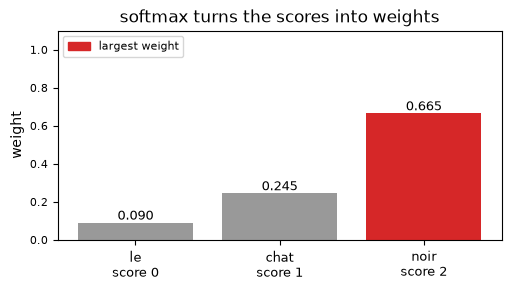

In [2]:
SCORES = [0, 1, 2]
weights_bars(SCORES)

### Solution

Scores 0, 1 and 2 give le 0.090, chat 0.245, noir 0.665: `noir` gets the most. Scores 3, 5 and 5 give a tie of `chat` and `noir` at 0.468, the weights of 0, 2 and 2. Scores 0, 2 and 4 give `noir` 0.867, where 4 over the sum is 0.667: the gaps between the scores set the weights, and each unit of gap multiplies the ratio of two weights by e, 2.718.

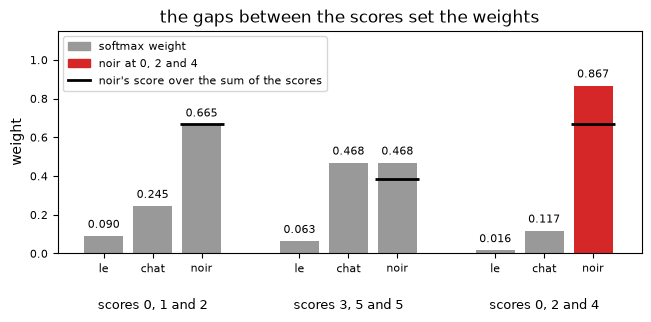

In [3]:
answer_scores([0, 1, 2], [3, 5, 5], [0, 2, 4])

## 2. A query scores the states, and the weights mix them into one vector

The decoder state that writes `black` is the query (0, 1). Its dot product
with an encoder state, the entries multiplied in pairs and added, is that
word's score; softmax turns the scores into weights, and the states added by
their weights give the context vector. Run the cell, then set `QUERY` to
`[2, 1]`, the query of the step that writes `cat`, and to `[1, 1]`. For each
query, which word scores highest, and does a tie appear?

dot products of the query (0, 1) with le (1, 0), chat (1, 1), noir (0, 2): 0, 1 and 2
weights: le 0.090, chat 0.245, noir 0.665
context vector: (0.335, 1.575)


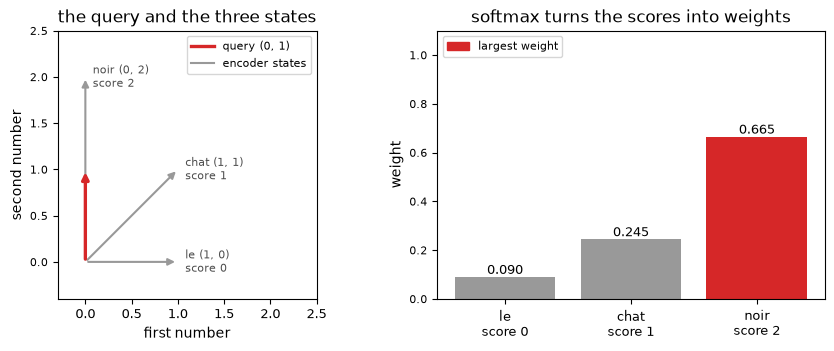

In [4]:
QUERY = [0, 1]
attend(QUERY)

### Solution

The query (0, 1) of `black` scores `le`, `chat` and `noir` 0, 1 and 2, `noir` highest, and reads (0.335, 1.575), nearest `noir`. The query (2, 1) of `cat` scores them 2, 3 and 2, `chat` highest, and reads (0.788, 1.000), nearest `chat`. The query (1, 1) scores them 1, 2 and 2, a tie of `chat` and `noir` at 0.422, and reads (0.578, 1.267), nearest `chat`. The weights are positive and add up to 1, so every context vector lies inside the triangle of the three states.

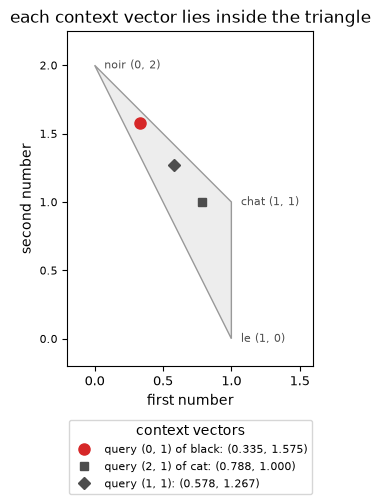

In [5]:
answer_queries([0, 1], [2, 1], [1, 1])